In [38]:
from datetime import datetime, timedelta
from pathlib import Path
from xml.etree import ElementTree as ET
import shutil

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from matplotlib.patches import Rectangle
from herbie import Herbie
from pyproj import Geod

# The NEW CrocoDash case, after you generate it.
# Do not create this directory with mkdir().
CASE = Path(
    "/glade/u/home/hmnguyen/work/crocodile2026/croc_cases/florida_storm_hrrr.003"
)

# Forcing products are separate from the case directory.
OUT = Path("/glade/work/hmnguyen/hrrr_forcing/florida_milton_u10")
CACHE = Path("/glade/work/hmnguyen/hrrr_cache")

START = datetime(2024, 10, 9, 0)  # UTC
N_HOURS = 4                       # 00, 01, 02, 03 UTC

# Geographic search box for selecting native HRRR cells.
WEST, EAST = 267.0, 286.0
SOUTH, NORTH = 20.0, 33.0
HALO = 2

# Proposed model-domain bounds. These do not control the HRRR download.
MODEL_WEST, MODEL_EAST = 267.0, 285.0
MODEL_SOUTH, MODEL_NORTH = 25.0, 32.0

U_SEARCH = r":UGRD:10 m above ground"
V_SEARCH = r":VGRD:10 m above ground"

U_FILE = OUT / "HRRR_U10_20241009_00-03.nc"
MESH_FILE = OUT / "HRRR_ESMFmesh.nc"

OUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

print("HRRR selection:", (WEST, EAST, SOUTH, NORTH))
print("MOM6 domain:   ", (MODEL_WEST, MODEL_EAST, MODEL_SOUTH, MODEL_NORTH))
print("Case exists:   ", CASE.is_dir())

HRRR selection: (267.0, 286.0, 20.0, 33.0)
MOM6 domain:    (267.0, 285.0, 25.0, 32.0)
Case exists:    True


In [29]:
h0 = Herbie(
    START,
    model="hrrr",
    product="sfc",
    fxx=0,
    save_dir=CACHE,
)

for search in (U_SEARCH, V_SEARCH):
    inventory = h0.inventory(search)
    print(f"\n{search}: {len(inventory)} match(es)")
    display(inventory)

    if len(inventory) != 1:
        raise ValueError(
            f"Expected exactly one GRIB message for {search}; "
            "inspect the displayed inventory before continuing."
        )

✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-09 00:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local

:UGRD:10 m above ground: 1 match(es)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
76,77,41270856,43652470.0,41270856-43652470,2024-10-09,2024-10-09,UGRD,10 m above ground,anl,:UGRD:10 m above ground:anl



:VGRD:10 m above ground: 1 match(es)


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
77,78,43652471,46034085.0,43652471-46034085,2024-10-09,2024-10-09,VGRD,10 m above ground,anl,:VGRD:10 m above ground:anl


In [30]:
def get_wind_flag(da, h, search):
    flag = da.attrs.get("GRIB_uvRelativeToGrid")

    if flag is None:
        try:
            from eccodes import (
                codes_grib_new_from_file,
                codes_get,
                codes_release,
            )
        except ImportError as exc:
            raise RuntimeError(
                "cfgrib did not expose GRIB_uvRelativeToGrid, and the "
                "Python eccodes package is unavailable. Stop here; do "
                "not guess the wind orientation."
            ) from exc

        grib_path = Path(h.get_localFilePath(search))
        if not grib_path.is_file():
            raise FileNotFoundError(grib_path)

        with grib_path.open("rb") as f:
            message = codes_grib_new_from_file(f)
            if message is None:
                raise RuntimeError(f"No GRIB message in {grib_path}")
            try:
                flag = codes_get(message, "uvRelativeToGrid")
            finally:
                codes_release(message)

    flag = int(flag)
    if flag not in (0, 1):
        raise ValueError(f"Unexpected uvRelativeToGrid={flag}")

    return flag  # 0: earth-relative; 1: grid-relative


def get_field(h, search):
    ds = h.xarray(search, remove_grib=False)

    if isinstance(ds, list):
        if len(ds) != 1:
            raise ValueError(f"{search} returned {len(ds)} datasets")
        ds = ds[0]

    names = list(ds.data_vars)
    if len(names) != 1:
        raise ValueError(f"{search} returned variables {names}")

    da = ds[names[0]].load()

    if da.dims != ("y", "x"):
        raise ValueError(f"Expected (y, x), found {da.dims}")

    flag = get_wind_flag(da, h, search)
    return da, flag


u0, u_flag = get_field(h0, U_SEARCH)
v0, v_flag = get_field(h0, V_SEARCH)

assert u_flag == v_flag, (u_flag, v_flag)

print("U variable:", u0.name, "| units:", u0.attrs.get("units"))
print("V variable:", v0.name, "| units:", v0.attrs.get("units"))
print("Wind orientation:", "grid-relative" if u_flag else "earth-relative")
print("Full HRRR array shape:", u0.shape)

U variable: u10 | units: m s**-1
V variable: v10 | units: m s**-1
Wind orientation: grid-relative
Full HRRR array shape: (1059, 1799)


In [31]:
lat_full = np.asarray(u0.latitude.values, dtype=np.float64)
lon_full = np.asarray(u0.longitude.values, dtype=np.float64) % 360.0

assert lat_full.shape == lon_full.shape == u0.shape
assert np.allclose(u0.latitude.values, v0.latitude.values)
assert np.allclose(u0.longitude.values, v0.longitude.values)

inside_search_box = (
    (lon_full >= WEST) & (lon_full <= EAST) &
    (lat_full >= SOUTH) & (lat_full <= NORTH)
)

jj, ii = np.where(inside_search_box)
if len(jj) == 0:
    raise ValueError("HRRR has no cells inside the geographic search box")

ys = slice(max(0, jj.min() - HALO), min(u0.shape[0], jj.max() + HALO + 1))
xs = slice(max(0, ii.min() - HALO), min(u0.shape[1], ii.max() + HALO + 1))

lat = lat_full[ys, xs]
lon = lon_full[ys, xs]

assert lat.shape == lon.shape
assert min(lat.shape) >= 2
assert np.isfinite(lat).all() and np.isfinite(lon).all()

print("Native HRRR subset shape (y, x):", lat.shape)
print("Index slices:", ys, xs)

Native HRRR subset shape (y, x): (421, 699)
Index slices: slice(0, np.int64(421), None) slice(np.int64(1038), np.int64(1737), None)


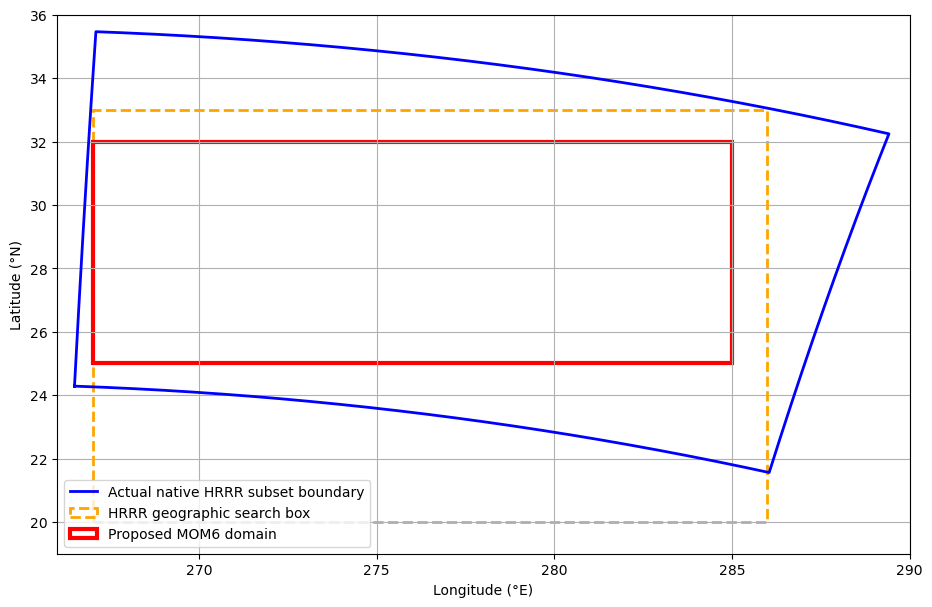

Proposed-domain points inside HRRR outline: 12851/12851


In [32]:
boundary_lon = np.concatenate([
    lon[0, :],
    lon[1:, -1],
    lon[-1, -2::-1],
    lon[-2:0:-1, 0],
])
boundary_lat = np.concatenate([
    lat[0, :],
    lat[1:, -1],
    lat[-1, -2::-1],
    lat[-2:0:-1, 0],
])

fig, ax = plt.subplots(figsize=(11, 7))

ax.plot(
    np.r_[boundary_lon, boundary_lon[0]],
    np.r_[boundary_lat, boundary_lat[0]],
    color="blue",
    linewidth=2,
    label="Actual native HRRR subset boundary",
)

ax.add_patch(Rectangle(
    (WEST, SOUTH),
    EAST - WEST,
    NORTH - SOUTH,
    fill=False,
    edgecolor="orange",
    linestyle="--",
    linewidth=2,
    label="HRRR geographic search box",
))

ax.add_patch(Rectangle(
    (MODEL_WEST, MODEL_SOUTH),
    MODEL_EAST - MODEL_WEST,
    MODEL_NORTH - MODEL_SOUTH,
    fill=False,
    edgecolor="red",
    linewidth=3,
    label="Proposed MOM6 domain",
))

ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)")
ax.set_xlim(266, 290)
ax.set_ylim(19, 36)
ax.grid(True)
ax.legend()
plt.show()

# Check a dense set of points across the proposed rectangular domain.
test_lon, test_lat = np.meshgrid(
    np.linspace(MODEL_WEST, MODEL_EAST, 181),
    np.linspace(MODEL_SOUTH, MODEL_NORTH, 71),
)
points = np.column_stack((test_lon.ravel(), test_lat.ravel()))

hrrr_outline = MplPath(
    np.column_stack((boundary_lon, boundary_lat)),
    closed=True,
)
covered = hrrr_outline.contains_points(points)

print(f"Proposed-domain points inside HRRR outline: "
      f"{covered.sum()}/{covered.size}")
assert covered.all(), "The proposed model domain extends outside this HRRR subset"

In [33]:
geod = Geod(ellps="WGS84")


def grid_winds_to_east(u_grid, v_grid, lat, lon):
    az_x = np.empty(lat.shape, dtype=np.float64)
    az_y = np.empty(lat.shape, dtype=np.float64)

    az_x[:, :-1], _, _ = geod.inv(
        lon[:, :-1], lat[:, :-1],
        lon[:, 1:], lat[:, 1:],
    )
    az_x[:, -1] = az_x[:, -2]

    az_y[:-1, :], _, _ = geod.inv(
        lon[:-1, :], lat[:-1, :],
        lon[1:, :], lat[1:, :],
    )
    az_y[-1, :] = az_y[-2, :]

    # Azimuth is degrees clockwise from geographic north.
    east_from_x = np.sin(np.deg2rad(az_x))
    east_from_y = np.sin(np.deg2rad(az_y))
    north_from_y = np.cos(np.deg2rad(az_y))

    if np.nanmin(east_from_x) <= 0 or np.nanmin(north_from_y) <= 0:
        raise ValueError("Unexpected x/y scanning directions; inspect the grid")

    return u_grid * east_from_x + v_grid * east_from_y

In [34]:
u_by_hour = []

for hour in range(N_HOURS):
    valid = START + timedelta(hours=hour)

    if hour == 0:
        u_da, v_da = u0, v0
        this_u_flag, this_v_flag = u_flag, v_flag
    else:
        h = Herbie(
            valid,
            model="hrrr",
            product="sfc",
            fxx=0,
            save_dir=CACHE,
        )
        u_da, this_u_flag = get_field(h, U_SEARCH)
        v_da, this_v_flag = get_field(h, V_SEARCH)

    if this_u_flag != u_flag or this_v_flag != u_flag:
        raise ValueError(f"Wind-orientation flags changed at {valid}")

    if not np.allclose(u_da.latitude.values[ys, xs], lat, atol=1e-5):
        raise ValueError(f"HRRR latitude grid changed at {valid}")
    if not np.allclose(u_da.longitude.values[ys, xs] % 360, lon, atol=1e-5):
        raise ValueError(f"HRRR longitude grid changed at {valid}")

    u_native = np.asarray(u_da.values[ys, xs], dtype=np.float64)
    v_native = np.asarray(v_da.values[ys, xs], dtype=np.float64)

    if not np.isfinite(u_native).all() or not np.isfinite(v_native).all():
        raise ValueError(f"Missing winds in rectangular HRRR subset at {valid}")

    if u_flag == 1:
        u_east = grid_winds_to_east(u_native, v_native, lat, lon)
    else:
        u_east = u_native

    u_by_hour.append(u_east.astype(np.float32))
    print(f"{valid:%Y-%m-%d %H:%M} UTC: completed")

u_data = np.stack(u_by_hour, axis=0)
assert u_data.shape == (N_HOURS, *lat.shape)

print("U10 array shape:", u_data.shape)
print("U10 range (m/s):", float(u_data.min()), float(u_data.max()))

2024-10-09 00:00 UTC: completed
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-09 01:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-09 01:00 UTC: completed
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-09 02:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-09 02:00 UTC: completed
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Oct-09 03:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local
2024-10-09 03:00 UTC: completed
U10 array shape: (4, 421, 699)
U10 range (m/s): -20.76494598388672 13.92131519317627


In [35]:
def centers_to_corners(a):
    """Estimate (ny+1, nx+1) corners from (ny, nx) centers."""
    ny, nx = a.shape
    expanded = np.empty((ny + 2, nx + 2), dtype=np.float64)

    expanded[1:-1, 1:-1] = a
    expanded[0, 1:-1] = 2 * a[0, :] - a[1, :]
    expanded[-1, 1:-1] = 2 * a[-1, :] - a[-2, :]
    expanded[:, 0] = 2 * expanded[:, 1] - expanded[:, 2]
    expanded[:, -1] = 2 * expanded[:, -2] - expanded[:, -3]

    return 0.25 * (
        expanded[:-1, :-1] +
        expanded[1:, :-1] +
        expanded[:-1, 1:] +
        expanded[1:, 1:]
    )


ny, nx = lat.shape

# Unwrap before averaging longitudes.
lon_unwrapped = np.rad2deg(
    np.unwrap(np.unwrap(np.deg2rad(lon), axis=1), axis=0)
)

corner_lat = centers_to_corners(lat)
corner_lon = centers_to_corners(lon_unwrapped)

# The current HRRR subset should have x increasing generally eastward
# and y increasing generally northward.
assert np.median(np.diff(lon_unwrapped, axis=1)) > 0
assert np.median(np.diff(lat, axis=0)) > 0

node_number = (
    np.arange((ny + 1) * (nx + 1), dtype=np.int32)
    .reshape(ny + 1, nx + 1) + 1
)

# SW, SE, NE, NW: counterclockwise connectivity.
element_conn = np.stack([
    node_number[:-1, :-1],
    node_number[:-1, 1:],
    node_number[1:, 1:],
    node_number[1:, :-1],
], axis=-1).reshape(ny * nx, 4)

node_coords = np.column_stack((
    (corner_lon % 360).ravel(order="C"),
    corner_lat.ravel(order="C"),
))
center_coords = np.column_stack((
    lon.ravel(order="C"),
    lat.ravel(order="C"),
))

mesh = xr.Dataset(
    data_vars={
        "nodeCoords": (
            ("nodeCount", "coordDim"),
            node_coords,
            {"units": "degrees"},
        ),
        "elementConn": (
            ("elementCount", "maxNodePElement"),
            element_conn,
            {"start_index": 1},
        ),
        "numElementConn": (
            ("elementCount",),
            np.full(ny * nx, 4, dtype=np.int32),
        ),
        "centerCoords": (
            ("elementCount", "coordDim"),
            center_coords,
            {"units": "degrees"},
        ),
        "elementMask": (
            ("elementCount",),
            np.ones(ny * nx, dtype=np.int32),
        ),
        "origGridDims": (
            ("origGridRank",),
            np.array([nx, ny], dtype=np.int32),
        ),
    },
    attrs={
        "gridType": "unstructured",
        "version": "0.9",
        "conventions": "ESMFMESH",
        "title": "Native rectangular HRRR Lambert subset",
    },
)

# These are mesh topology variables, not fields with missing data.
encoding = {name: {"_FillValue": None} for name in mesh.variables}
mesh.to_netcdf(
    MESH_FILE,
    format="NETCDF4_CLASSIC",
    encoding=encoding,
)

print(MESH_FILE)
print("Elements:", mesh.sizes["elementCount"])
print("Nodes:   ", mesh.sizes["nodeCount"])

/glade/work/hmnguyen/hrrr_forcing/florida_milton_u10/HRRR_ESMFmesh.nc
Elements: 294279
Nodes:    295400


In [39]:
env_run = CASE / "env_run.xml"
if not env_run.is_file():
    raise FileNotFoundError(
        f"{env_run}\nGenerate and set up the .003 case before this cell."
    )

entries = {
    entry.get("id"): entry.get("value")
    for entry in ET.parse(env_run).iter("entry")
}

case_calendar = entries.get("CALENDAR")
print("Case CALENDAR:     ", case_calendar)
print("Case RUN_STARTDATE:", entries.get("RUN_STARTDATE"))

if not case_calendar:
    raise ValueError("Could not read CALENDAR from env_run.xml")

calendar_key = case_calendar.strip().lower()
if calendar_key in ("no_leap", "noleap", "365_day"):
    cf_calendar = "noleap"
elif calendar_key in ("gregorian", "standard"):
    cf_calendar = "gregorian"
else:
    raise ValueError(
        f"Check how to represent case calendar {case_calendar!r} in CF time"
    )

forcing = xr.Dataset(
    data_vars={
        "U_10": (
            ("time", "y", "x"),
            u_data,
            {
                "units": "m s-1",
                "long_name": "10 m eastward wind",
            },
        ),
    },
    coords={
        "time": (
            ("time",),
            np.arange(N_HOURS, dtype=np.float64),
            {
                "units": f"hours since {START:%Y-%m-%d %H:%M:%S}",
                "calendar": cf_calendar,
            },
        ),
        "latitude": (
            ("y", "x"),
            lat,
            {"units": "degrees_north"},
        ),
        "longitude": (
            ("y", "x"),
            lon,
            {"units": "degrees_east"},
        ),
    },
    attrs={
        "source": "HRRR sfc f00 analysis, native Lambert grid",
        "wind_orientation": "geographic eastward",
    },
)

forcing.to_netcdf(
    U_FILE,
    format="NETCDF4_CLASSIC",
    encoding={
        "U_10": {
            "zlib": True,
            "complevel": 2,
            "_FillValue": np.float32(1e20),
        }
    },
)

print(U_FILE)

Case CALENDAR:      GREGORIAN
Case RUN_STARTDATE: 2024-10-09
/glade/work/hmnguyen/hrrr_forcing/florida_milton_u10/HRRR_U10_20241009_00-03.nc


In [40]:
with xr.open_dataset(U_FILE, decode_times=False) as data_check, \
     xr.open_dataset(MESH_FILE, decode_times=False) as mesh_check:

    assert data_check["U_10"].dims == ("time", "y", "x")
    assert data_check["U_10"].shape == (N_HOURS, ny, nx)
    assert mesh_check.sizes["elementCount"] == ny * nx

    centers = mesh_check["centerCoords"].values
    np.testing.assert_allclose(centers[:, 0], lon.ravel(order="C"))
    np.testing.assert_allclose(centers[:, 1], lat.ravel(order="C"))

    np.testing.assert_array_equal(
        mesh_check["origGridDims"].values,
        [nx, ny],
    )

    print("Time values:", data_check.time.values)
    print("Time units:", data_check.time.attrs["units"])
    print("Calendar:", data_check.time.attrs["calendar"])
    print("First mesh center:", centers[0])
    print("First field value:", float(data_check.U_10.values[0, 0, 0]))

print("Field dimensions and mesh ordering agree.")

Time values: [0. 1. 2. 3.]
Time units: hours since 2024-10-09 00:00:00
Calendar: gregorian
First mesh center: [266.49169554  24.28567654]
First field value: 0.2884577214717865
Field dimensions and mesh ordering agree.


In [44]:
from xml.etree import ElementTree as ET

generated_xml = CASE / "CaseDocs" / "datm.streams.xml"
override_file = CASE / "user_nl_datm_streams"

assert generated_xml.is_file()
assert U_FILE.is_file()
assert MESH_FILE.is_file()

root = ET.parse(generated_xml).getroot()

matches = [
    stream
    for stream in root.iter("stream_info")
    if any(
        (var.text or "").split()[-1:] == ["Sa_u"]
        for var in stream.findall("./datavars/var")
    )
]
assert len(matches) == 1, f"Found {len(matches)} Sa_u streams"

stream_name = matches[0].get("name")
assert stream_name
print("Overriding:", stream_name)

existing = override_file.read_text() if override_file.exists() else ""

# Stop rather than silently creating conflicting overrides.
if any(
    line.strip().startswith(f"{stream_name}:")
    for line in existing.splitlines()
):
    raise ValueError(
        f"{override_file} already has entries for {stream_name}. "
        "Inspect those entries before adding another set."
    )

settings = {
    "taxmode": "limit",
    "tintalgo": "linear",
    "readmode": "single",
    "mapalgo": "bilinear",
    "year_first": "2024",
    "year_last": "2024",
    "year_align": "2024",
    "meshfile": str(MESH_FILE),
    "datafiles": str(U_FILE),
    "datavars": "U_10 Sa_u",
}

new_lines = [
    f"{stream_name}:{key} = {value}"
    for key, value in settings.items()
]

override_file.write_text(
    existing.rstrip() + "\n\n"
    + "! HRRR U10 plumbing test\n"
    + "\n".join(new_lines) + "\n"
)

print(override_file.read_text())

Overriding: CORE_IAF_JRA_1p5_2023.NCEP.U_10
!------------------------------------------------------------------------
! This file is used to modify datm.streams.xml generated in $RUNDIR
! Entries should have the form
!  <streamname>:<stream_variable>= <new stream_value> (NO Quotes!!!)
! The following are accepted values for a stream named foo
!  foo:meshfile = character string
!  foo:datafiles = comma separated string of full pathnames (e.g. file1,file2,file3...)
!  foo:datavars = comma separated string of field pairs  (e.g. foo foobar,foo2 foobar2...)
!  foo:taxmode = one of [cycle, extend, limit]
!  foo:tintalgo = one of [lower,upper,nearest,linear,coszen]
!  foo:readmode = single (only suported mode right now)
!  foo:mapalgo = one of [bilinear,redist,nn,consf,consd,none]
!  foo:dtlimit = real (1.5 is default)
!  foo:year_first = integer
!  foo:year_last = integer
!  foo:year_align = integer
!  foo:vectors = null or the names of the vector fields in the model (i.e. Sa_u:Sa_v)
!  foo:

In [45]:
old_override = CASE / "datm.streams.xml"
saved_override = CASE / "datm.streams.xml.previous_attempt"

if old_override.exists():
    if saved_override.exists():
        raise FileExistsError(saved_override)
    old_override.rename(saved_override)
    print("Saved previous attempt as:", saved_override)

Saved previous attempt as: /glade/u/home/hmnguyen/work/crocodile2026/croc_cases/florida_storm_hrrr.003/datm.streams.xml.previous_attempt


In [47]:
checked_tree = ET.parse(CASE / "CaseDocs" / "datm.streams.xml")

u_streams = [
    stream
    for stream in checked_tree.iter("stream_info")
    if any(
        (var.text or "").split()[-1:] == ["Sa_u"]
        for var in stream.findall("./datavars/var")
    )
]

assert len(u_streams) == 1
checked = u_streams[0]

for tag in (
    "taxmode", "tintalgo", "mapalgo",
    "year_first", "year_last", "year_align",
    "meshfile",
):
    print(f"{tag:12s}: {checked.findtext(tag)}")

print("datafile    :", checked.findtext("./datafiles/file"))
print(
    "variable    :",
    [var.text for var in checked.findall("./datavars/var")],
)

assert checked.findtext("meshfile") == str(MESH_FILE)
assert checked.findtext("./datafiles/file") == str(U_FILE)
assert any(
    (var.text or "").split() == ["U_10", "Sa_u"]
    for var in checked.findall("./datavars/var")
)

print("Generated CaseDocs uses HRRR for Sa_u.")

taxmode     : limit
tintalgo    : linear
mapalgo     : bilinear
year_first  : 2024
year_last   : 2024
year_align  : 2024
meshfile    : /glade/work/hmnguyen/hrrr_forcing/florida_milton_u10/HRRR_ESMFmesh.nc
datafile    : /glade/work/hmnguyen/hrrr_forcing/florida_milton_u10/HRRR_U10_20241009_00-03.nc
variable    : ['U_10 Sa_u']
Generated CaseDocs uses HRRR for Sa_u.


In [60]:
from pathlib import Path
import re
import xml.etree.ElementTree as ET

root = ET.parse(CASE / "CaseDocs/datm.streams.xml").getroot()
prefix = "CORE_IAF_JRA_1p5_2023."
expected = {"PREC", "LWDN", "SWDN", "Q_10", "SLP_", "T_10", "V_10"}

streams = [
    s for s in root.iter("stream_info")
    if s.get("name", "").startswith(prefix)
    and s.get("name", "").split(".")[-1] in expected
]
assert {s.get("name").split(".")[-1] for s in streams} == expected

lines = []
for stream in streams:
    name = stream.get("name")
    files = [
        f.text for f in stream.findall("./datafiles/file")
        if f.text and re.search(r"\.2023\.", Path(f.text).name)
    ]
    assert len(files) == 1, (name, files)

    lines.extend([
        f"{name}:taxmode = cycle",
        f"{name}:year_first = 2023",
        f"{name}:year_last = 2023",
        f"{name}:year_align = 2024",
        f"{name}:datafiles = {files[0]}",
    ])

path = CASE / "user_nl_datm_streams"
marker = "! Milton U10 test: one-year JRA background"
current = path.read_text()

if marker not in current:
    path.write_text(current.rstrip() + "\n\n" + marker + "\n"
                    + "\n".join(lines) + "\n")
else:
    assert all(line in current for line in lines), "Existing background block differs"

print("Configured", len(streams), "JRA background streams")
print("Existing HRRR U10 override preserved")

Configured 7 JRA background streams
Existing HRRR U10 override preserved


In [62]:
regional_mesh = str(Path(ocean_mesh))
datm_text = (CASE / "CaseDocs/datm_in").read_text()

for key in ("model_meshfile", "model_maskfile"):
    match = re.search(
        rf'''(?im)^\s*{key}\s*=\s*["']([^"']+)["']''',
        datm_text,
    )
    assert match, f"{key} missing"
    print(key, "=", match.group(1))
    assert match.group(1) == regional_mesh

root = ET.parse(CASE / "CaseDocs/datm.streams.xml").getroot()

for stream in root.iter("stream_info"):
    name = stream.get("name", "")
    if not name.startswith(prefix):
        continue

    files = [
        f.text for f in stream.findall("./datafiles/file") if f.text
    ]
    field = name.split(".")[-1]

    if field in expected:
        assert len(files) == 1 and ".2023." in Path(files[0]).name
        assert stream.findtext("year_align") == "2024"
        print(field, "→ JRA 2023; one file")

    elif field == "U_10":
        assert len(files) == 1 and "HRRR_U10_" in Path(files[0]).name
        assert stream.findtext("meshfile") == str(Path(u.findtext("meshfile")))
        assert stream.findtext("year_first") == "2024"
        print("U_10 → HRRR 2024; one file")

print("Namelist checks passed")

model_meshfile = /glade/work/hmnguyen/crocodile2026/croc_input/florida_storm_hrrr.003/ocn/ESMF_mesh_florida_milton_hrrr2_0a8246.nc
model_maskfile = /glade/work/hmnguyen/crocodile2026/croc_input/florida_storm_hrrr.003/ocn/ESMF_mesh_florida_milton_hrrr2_0a8246.nc
PREC → JRA 2023; one file
LWDN → JRA 2023; one file
SWDN → JRA 2023; one file
Q_10 → JRA 2023; one file
SLP_ → JRA 2023; one file
T_10 → JRA 2023; one file
U_10 → HRRR 2024; one file
V_10 → JRA 2023; one file
Namelist checks passed


In [67]:
from pathlib import Path
import shutil
import numpy as np
from netCDF4 import Dataset

OCEAN_MESH = Path(
    "/glade/work/hmnguyen/crocodile2026/croc_input/"
    "florida_storm_hrrr.003/ocn/"
    "ESMF_mesh_florida_milton_hrrr2_0a8246.nc"
)
ATM_MESH = Path(
    "/glade/work/hmnguyen/hrrr_forcing/florida_milton_u10/"
    "Florida_regional_ATM_ESMFmesh.nc"
)

assert OCEAN_MESH.exists()
assert OCEAN_MESH != ATM_MESH

shutil.copy2(OCEAN_MESH, ATM_MESH)

with Dataset(ATM_MESH, "r+") as mesh:
    mask = mesh.variables["elementMask"]
    mask[:] = np.ones(mask.shape, dtype=mask.dtype)

with Dataset(ATM_MESH) as mesh:
    values, counts = np.unique(
        mesh.variables["elementMask"][:], return_counts=True
    )
    print("Atmosphere mask:", dict(zip(values.tolist(), counts.tolist())))

Atmosphere mask: {1: 32256}
